# Transit Coverage Visualization Tool

Created 10/28/2026

Author: Rae Holcomb

Purpose: This notebook contains functions which allow you to quickly assess how much coverage of the baseline, ingress/egress, and bottom of a transit a particular observation (or list of observations) from the short term scheduler will cover.

Requires: pandoravisibility, CSV of planned observations from the short term scheduler, an up to date TLE, internet access (to query the Exoplanet Archive.)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
import re
import requests
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.time import Time, TimeDelta
from astropy.visualization import time_support

# Suppress warnings for clean notebook output
warnings.filterwarnings('ignore')

# set up TAP
from pyvo.dal import TAPService
tap_url = "https://exoplanetarchive.ipac.caltech.edu/TAP"
tap_service = TAPService(tap_url)

In [2]:
# Set up pandoravisibility
from pandoravisibility import Visibility, analyze_yearly_visibility, plot_yearly_visibility

# Replace this with an up-to-date TLE from KSAT
line1 = "1 67395U 80229J   26300.68643519  .00000000  00000-0 -18693-5 0    00"
line2 = "2 67395  97.8121 297.3626 0006715  58.8024 247.1546 14.88241736    04"

# initialize the Visibility object
vis = Visibility(line1, line2)
print(vis)
print(f"Orbital period: {vis.get_period():.2f}")

<Visibility: SAT67395 [moon≥20 deg, sun≥91 deg, limb=dynamic, st_sun≥50 deg, st_moon≥20 deg, st_limb≥30 deg, st_req=1]>
Orbital period: 96.76 min


In [3]:
# HELPER FUNCTIONS
def clean_target_name(target_name):
    clean_name = str(target_name).replace('_', ' ')
    if clean_name[-1].islower() and len(clean_name) >= 2 and clean_name[-2] != ' ':
        clean_name = clean_name[:-1] + ' ' + clean_name[-1]
    return clean_name

def generate_name_permutations(target_name):
    dense = re.sub(r'[-\s_]+', '', str(target_name))
    parts = re.findall(r'[a-zA-Z]+|\d+', dense)
    perms = set([str(target_name)])
    if len(parts) == 3:
        host, num, letter = parts
        perms.update([f"{host}-{num} {letter}", f"{host} {num} {letter}", 
                      f"{host}-{num}{letter}", f"{host} {num}{letter}", f"{host}{num}{letter}"])
    return perms

def is_complete(params):
    """Helper to ensure we have the minimum required timing parameters."""
    if not params: return False
    return (params.get('pl_orbper') is not None and 
            params.get('pl_tranmid') is not None and 
            params.get('pl_trandur') is not None)

def batch_query_exoplanet_archive(target_list):
    """
    Batch queries the Exoplanet Archive, aggregating data across multiple 
    papers to fill in missing transit parameters.
    """
    url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
    unique_targets = list(set([t for t in target_list if pd.notna(t) and 'Free Time' not in str(t)]))
    
    results_cache = {}
    remaining_targets = set(unique_targets)
    
    if not remaining_targets: return results_cache

    def ingest_ps_rows(resp, name_mapping):
        """Helper to process PS table rows and fill in missing parameters."""
        if resp.status_code == 200:
            for row in resp.json():
                orig_name = name_mapping.get(row['pl_name'])
                if not orig_name: continue
                
                # Initialize the target in our cache if it's the first time seeing it
                if orig_name not in results_cache:
                    results_cache[orig_name] = {
                        'pl_name': row.get('pl_name'),
                        'pl_orbper': None, 'pl_tranmid': None, 
                        'pl_trandur': None, 'pl_ratror': None
                    }
                
                # Fill forward: if our cache has a None value, see if this paper has it!
                for key in ['pl_orbper', 'pl_tranmid', 'pl_trandur', 'pl_ratror']:
                    if results_cache[orig_name][key] is None and row.get(key) is not None:
                        results_cache[orig_name][key] = row[key]

    # --- Step 1: Batch Query Clean Names ---
    clean_to_orig = {clean_target_name(t): t for t in remaining_targets}
    clean_sql_list = ", ".join([f"'{c}'" for c in clean_to_orig.keys()])
    
    # We remove the LIMIT/first-row restriction to get all papers for aggregation
    query_ps_clean = f"SELECT pl_name, pl_orbper, pl_tranmid, pl_trandur, pl_ratror FROM ps WHERE pl_name IN ({clean_sql_list}) ORDER BY default_flag DESC"
    resp_clean = requests.post(url, data={"query": query_ps_clean, "format": "json"})
    
    ingest_ps_rows(resp_clean, clean_to_orig)
    
    # Only remove targets from the search queue if we successfully found their core timing parameters
    for orig_name in list(remaining_targets):
        if orig_name in results_cache and is_complete(results_cache[orig_name]):
            remaining_targets.discard(orig_name)

    # --- Step 2: Batch Query Unconfirmed TOI Candidates ---
    if remaining_targets:
        toi_to_orig = {}
        for t in list(remaining_targets):
            dense = re.sub(r'[-\s_]+', '', str(t).upper())
            if dense.startswith('TOI'):
                parts = re.findall(r'[A-Z]+|\d+', dense)
                if len(parts) == 3 and parts[0] == 'TOI':
                    toi_num, letter = parts[1], parts[2]
                    if len(letter) == 1 and letter.isalpha():
                        candidate_num = ord(letter) - ord('B') + 1
                        toi_id = f"{toi_num}.{candidate_num:02d}"
                        toi_to_orig[toi_id] = t
                        
        if toi_to_orig:
            toi_sql_list = ", ".join([f"'{tid}'" for tid in toi_to_orig.keys()])
            query_toi = f"SELECT * FROM toi WHERE toi IN ({toi_sql_list})"
            resp_toi = requests.post(url, data={"query": query_toi, "format": "json"})
            
            if resp_toi.status_code == 200:
                for row in resp_toi.json():
                    orig_name = toi_to_orig.get(row['toi'])
                    if orig_name:
                        duration = row.get('pl_trandurh') or row.get('pl_trandur')
                        midpoint = row.get('pl_tranmid') or row.get('toi_tranmid')
                        
                        results_cache[orig_name] = {
                            'pl_name': f"TOI {row['toi']}",
                            'pl_orbper': row.get('pl_orbper'),
                            'pl_tranmid': midpoint,
                            'pl_trandur': duration,
                            'pl_ratror': None
                        }
                        if is_complete(results_cache[orig_name]):
                            remaining_targets.discard(orig_name)

    # --- Step 3: Batch Query Permutations ---
    if remaining_targets:
        perm_to_orig = {}
        for t in list(remaining_targets):
            for p in generate_name_permutations(t):
                perm_to_orig[p] = t
                
        if perm_to_orig:
            perms_sql_list = ", ".join([f"'{p}'" for p in perm_to_orig.keys()])
            query_ps_perms = f"SELECT pl_name, pl_orbper, pl_tranmid, pl_trandur, pl_ratror FROM ps WHERE pl_name IN ({perms_sql_list}) ORDER BY default_flag DESC"
            resp_perms = requests.post(url, data={"query": query_ps_perms, "format": "json"})
            
            ingest_ps_rows(resp_perms, perm_to_orig)
            
            for orig_name in list(remaining_targets):
                if orig_name in results_cache and is_complete(results_cache[orig_name]):
                    remaining_targets.discard(orig_name)
                    
    # Log any targets that still entirely failed after aggregation
    for failed in remaining_targets:
        print(f"Warning: Could not compile complete transit timing for {failed}")

    return results_cache

def get_planet_params(df):
    """Takes in the target DF and queries the exoplanet archive for planet parameters."""
    # # Load the observation schedule
    # df = pd.read_csv(csv_path)
    
    # Extract unique targets and perform the batch query
    unique_targets = np.delete(df['Target'].unique(), np.where(df['Target'].unique() == 'Free Time')).tolist()
    print(f"Batch querying parameters for {len(unique_targets)} unique targets...")
    param_cache = batch_query_exoplanet_archive(unique_targets)

    return param_cache

def get_overlap(start1, end1, start2, end2):
    """Helper to find overlapping duration between two time windows."""
    return max(0.0, min(end1, end2) - max(start1, start2))

def analyze_and_plot_observations_NO_VIS(df, param_cache, plot=True):
    """
    Takes the observation schedule and planet parameters, calculates 
    transit coverage percentages, and plots each observation window.
    """
    results = []
    
    for index, row in df.iterrows():
        target = row['Target']
        
        # Skip empty or Free Time blocks
        if pd.isna(target) or 'Free Time' in str(target):
            continue
            
        params = param_cache.get(target)
        if not params or not params.get('pl_orbper') or not params.get('pl_trandur'):
            print(f"Skipping {target}: Missing essential transit parameters.")
            continue
            
        # Parse observation times to Julian Date
        try:
            obs_start = Time(row['Observation Start'], format='iso', scale='utc').jd
            obs_stop = Time(row['Observation Stop'], format='iso', scale='utc').jd
        except ValueError:
            print(f"Skipping {target}: Invalid date format.")
            continue
            
        obs_dur = obs_stop - obs_start
        
        # Extract transit variables
        period = params['pl_orbper'] # days
        t0 = params['pl_tranmid'] # JD
        t14_hours = params['pl_trandur'] # hours
        rp_rs = params['pl_ratror'] # Rp / Rs
        
        t14_days = t14_hours / 24.0
        
        # Approximate T23 (bottom duration) and transit depth
        if rp_rs and not pd.isna(rp_rs):
            t23_days = t14_days * ((1 - rp_rs) / (1 + rp_rs))
            depth = rp_rs ** 2
        else:
            t23_days = t14_days * 0.8 
            depth = 0.01 # Placeholder 1% depth for plotting if radius ratio is missing
            
        # Find the specific transit midpoint (Tc) closest to the observation window
        window_mid = (obs_start + obs_stop) / 2.0
        epochs_since = round((window_mid - t0) / period)
        current_t0 = t0 + (epochs_since * period)
        
        # Calculate transit contact times in JD
        t1 = current_t0 - (t14_days / 2.0)
        t4 = current_t0 + (t14_days / 2.0)
        t2 = current_t0 - (t23_days / 2.0)
        t3 = current_t0 + (t23_days / 2.0)
        
        # Calculate overlaps
        total_transit_overlap = get_overlap(obs_start, obs_stop, t1, t4)
        bottom_overlap = get_overlap(obs_start, obs_stop, t2, t3)
        ing_egr_overlap = total_transit_overlap - bottom_overlap
        oot_overlap = obs_dur - total_transit_overlap
        
        # Calculate percentages
        pct_bottom = (bottom_overlap / obs_dur) * 100
        pct_ing_egr = (ing_egr_overlap / obs_dur) * 100
        pct_oot = (oot_overlap / obs_dur) * 100
        
        # Append to results
        results.append({
            'Target': target,
            'Obs Start': row['Observation Start'],
            'Obs Stop': row['Observation Stop'],
            'Out-of-Transit (%)': round(pct_oot, 1),
            'Ingress/Egress (%)': round(pct_ing_egr, 1),
            'Transit Bottom (%)': round(pct_bottom, 1)
        })
        
        # ---------------------------------------------------------
        # PLOTTING
        # ---------------------------------------------------------
        if plot:
            # Convert times to hours relative to the transit midpoint for plotting
            t1_hr = -t14_hours / 2.0
            t4_hr = t14_hours / 2.0
            t2_hr = -(t23_days * 24.0) / 2.0
            t3_hr = (t23_days * 24.0) / 2.0
            
            obs_start_hr = (obs_start - current_t0) * 24.0
            obs_stop_hr = (obs_stop - current_t0) * 24.0
            
            # Define the trapezoid points for the transit model
            padding = max(2.0, (obs_stop_hr - obs_start_hr) * 0.2)
            x_min = min(obs_start_hr, t1_hr) - padding
            x_max = max(obs_stop_hr, t4_hr) + padding
            
            model_x = [x_min, t1_hr, t2_hr, t3_hr, t4_hr, x_max]
            model_y = [1.0, 1.0, 1.0 - depth, 1.0 - depth, 1.0, 1.0]
            
            # Create the figure
            fig, ax = plt.subplots(figsize=(10, 3))
            
            # Plot the transit model
            ax.plot(model_x, model_y, color='black', lw=2, label='Transit Model')
            
            # Highlight the observation window
            ax.axvspan(obs_start_hr, obs_stop_hr, color='cornflowerblue', alpha=0.4, 
                    label=f'Obs Window\n(OOT: {pct_oot:.0f}%, I/E: {pct_ing_egr:.0f}%, Bot: {pct_bottom:.0f}%)')
            
            # Add labels and formatting
            ax.set_title(f"{target} | Obs Start: {row['Observation Start']}")
            ax.set_xlabel("Hours from Transit Midpoint")
            ax.set_ylabel("Relative Flux")
            ax.set_xlim(x_min, x_max)
            
            # Ensure y-axis covers the transit depth with some margin
            ax.set_ylim(1.0 - (depth * 1.5), 1.0 + (depth * 0.5))
            
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='lower left')
            
            plt.tight_layout()
            plt.show()

    return pd.DataFrame(results)

def analyze_and_plot_observations(df, param_cache, plot=True, rows=None):
    """
    Analyzes observation schedules integrating Earth-occultation visibility.
    Includes granular reporting for Baseline, Ingress, Bottom, and Egress.
    """
    if rows is not None:
        df_filtered = df.iloc[rows]
    else:
        df_filtered = df
        
    results = []
    
    for index, row in df_filtered.iterrows():
        target = row['Target']
        
        if pd.isna(target) or 'Free Time' in str(target):
            continue
            
        ra, dec = row['RA'], row['DEC']
        if pd.isna(ra) or pd.isna(dec):
            continue
            
        params = param_cache.get(target)
        if not params or not params.get('pl_orbper') or not params.get('pl_trandur'):
            continue
            
        try:
            tstart = Time(row['Observation Start'], format='iso', scale='utc')
            tstop = Time(row['Observation Stop'], format='iso', scale='utc')
        except ValueError:
            continue
            
        # ---------------------------------------------------------
        # 1. TIMESTEPS & VISIBILITY
        # ---------------------------------------------------------
        duration_min = (tstop - tstart).to_value(u.min)
        if duration_min <= 0:
            continue
            
        deltas = np.arange(0, duration_min, 1) * u.min
        times = tstart + TimeDelta(deltas)
        
        state = vis.get_state(times)
        target_coord = SkyCoord(ra, dec, frame="icrs", unit="deg")
        targ_vis = vis.get_visibility(target_coord, times)["visible"]
        
        # ---------------------------------------------------------
        # 2. TRANSIT TIMING MATH
        # ---------------------------------------------------------
        period = params['pl_orbper'] 
        t0 = params['pl_tranmid'] 
        t14_hours = params['pl_trandur'] 
        rp_rs = params['pl_ratror'] 
        
        t14_days = t14_hours / 24.0
        if rp_rs and not pd.isna(rp_rs):
            t23_days = t14_days * ((1 - rp_rs) / (1 + rp_rs))
            depth = rp_rs ** 2
        else:
            t23_days = t14_days * 0.8 
            depth = 0.01 
            
        # The true "total" duration of these physical events in minutes
        total_ing_min = ((t14_days - t23_days) / 2.0) * 24 * 60
        total_egr_min = total_ing_min
        total_bot_min = t23_days * 24 * 60
            
        window_mid = (tstart.jd + tstop.jd) / 2.0
        epochs_since = round((window_mid - t0) / period)
        current_t0 = t0 + (epochs_since * period)
        
        # ---------------------------------------------------------
        # 3. DISCRETE EVENT CAPTURE CALCULATIONS
        # ---------------------------------------------------------
        # Boolean arrays mapping what part of the transit is happening at each minute
        is_ing = (times.jd >= current_t0 - t14_days/2.0) & (times.jd < current_t0 - t23_days/2.0)
        is_bot = (times.jd >= current_t0 - t23_days/2.0) & (times.jd <= current_t0 + t23_days/2.0)
        is_egr = (times.jd > current_t0 + t23_days/2.0) & (times.jd <= current_t0 + t14_days/2.0)
        is_oot = ~(is_ing | is_bot | is_egr)
        
        # Combine event timing with the spacecraft visibility mask
        obs_ing_min = np.sum(is_ing & targ_vis)
        obs_egr_min = np.sum(is_egr & targ_vis)
        obs_bot_min = np.sum(is_bot & targ_vis)
        obs_oot_min = np.sum(is_oot & targ_vis)
        
        # Final Metrics Calculation
        baseline_hrs = obs_oot_min / 60.0
        pct_baseline = (obs_oot_min / duration_min * 100) if duration_min > 0 else 0
        
        pct_ing_cap = (obs_ing_min / total_ing_min * 100) if total_ing_min > 0 else 0
        pct_egr_cap = (obs_egr_min / total_egr_min * 100) if total_egr_min > 0 else 0
        pct_bot_cap = (obs_bot_min / total_bot_min * 100) if total_bot_min > 0 else 0
        
        results.append({
            'Row': index,
            'Target': target,
            'Obs Start': row['Observation Start'],
            'Baseline (hrs)': round(baseline_hrs, 2),
            'Baseline (%)': round(pct_baseline, 1),
            'Ingress Cap (min)': int(obs_ing_min),
            'Ingress Cap (%)': round(pct_ing_cap, 1),
            'Bottom Cap (min)': int(obs_bot_min),
            'Bottom Cap (%)': round(pct_bot_cap, 1),
            'Egress Cap (min)': int(obs_egr_min),
            'Egress Cap (%)': round(pct_egr_cap, 1)
        })
        
        # ---------------------------------------------------------
        # 4. PLOTTING
        # ---------------------------------------------------------
        if plot:
            times_hr = (times.jd - current_t0) * 24.0
            
            t1_hr = -t14_hours / 2.0
            t4_hr = t14_hours / 2.0
            t2_hr = -(t23_days * 24.0) / 2.0
            t3_hr = (t23_days * 24.0) / 2.0
            
            padding = max(2.0, duration_min / 60.0 * 0.2)
            x_min = min(times_hr[0], t1_hr) - padding
            x_max = max(times_hr[-1], t4_hr) + padding
            
            model_x = [x_min, t1_hr, t2_hr, t3_hr, t4_hr, x_max]
            model_y = [1.0, 1.0, 1.0 - depth, 1.0 - depth, 1.0, 1.0]
            
            fig, ax = plt.subplots(figsize=(10, 3.5))
            ax.plot(model_x, model_y, color='black', lw=2, label='Transit Model')
            
            changes = np.where(targ_vis[:-1] != targ_vis[1:])[0] + 1
            blocks = np.split(np.arange(len(targ_vis)), changes)
            
            vis_label_added = False
            nonvis_label_added = False
            
            for block in blocks:
                if len(block) == 0: continue
                
                is_vis = targ_vis[block[0]]
                b_start = times_hr[block[0]]
                b_end = times_hr[block[-1]] + (1.0 / 60.0) 
                
                if is_vis:
                    label = 'Observable' if not vis_label_added else None
                    ax.axvspan(b_start, b_end, color='cornflowerblue', alpha=0.5, label=label)
                    vis_label_added = True
                else:
                    label = 'Obscured (Earth Block)' if not nonvis_label_added else None
                    ax.axvspan(b_start, b_end, color='lightcoral', hatch='//', alpha=0.4, label=label)
                    nonvis_label_added = True

            # Dynamic title mapping the new expanded metrics
            title = (f"Row {index}: {target} | Start: {row['Observation Start']}\n"
                     f"Base: {baseline_hrs:.1f}h ({pct_baseline:.0f}%) | "
                     f"Ing: {int(obs_ing_min)}m ({pct_ing_cap:.0f}%) | "
                     f"Bot: {int(obs_bot_min)}m ({pct_bot_cap:.0f}%) | "
                     f"Egr: {int(obs_egr_min)}m ({pct_egr_cap:.0f}%)")
            
            ax.set_title(title)
            ax.set_xlabel("Hours from Transit Midpoint")
            ax.set_ylabel("Relative Flux")
            ax.set_xlim(x_min, x_max)
            ax.set_ylim(1.0 - (depth * 1.5), 1.0 + (depth * 0.5))
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='lower left')
            
            plt.tight_layout()
            plt.show()

    return pd.DataFrame(results)


**1. Load the observation schedule**

In [ ]:
# Replace this path with the schedule you want to analyze
csv_path = "../../pandora-sandbox/Pandora_Schedule_0.8_0.0_0.2_2026-10-12_to_2027-04-11.csv"
df0 = pd.read_csv(csv_path)
df = df0[df0.Target != 'Free Time'].reset_index(drop=True)


Batch querying parameters for 50 unique targets...


**2. Get the planet parameters (Your modular function)**

Note that this may take a while to query the Exoplanet Archive if the schedule is large and contains many targets.

In [9]:
param_cache = get_planet_params(df)

Batch querying parameters for 50 unique targets...


**3. Analyze overlaps and plot the results**

* Use the `plot` keywork to toggle plotting on/off. 
* Use the `rows` keyword to analyze specific rows (e.g., `rows=[0, 1, 2, 3, 4]` to analyize the first 5 rows)
* `rows=None` will analyze all rows in the schedule

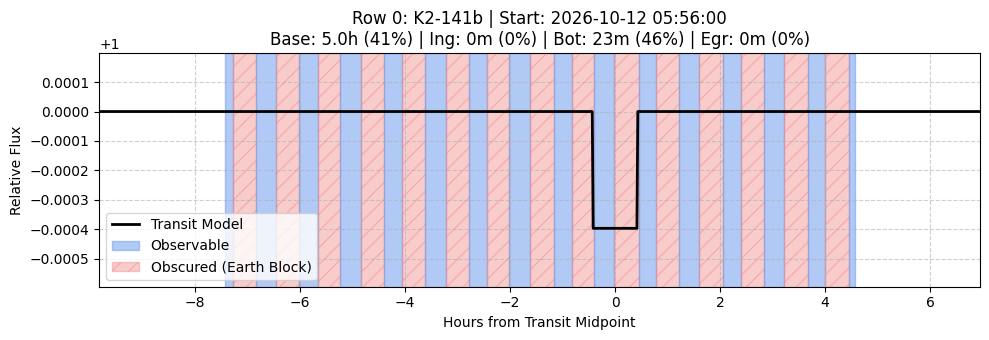

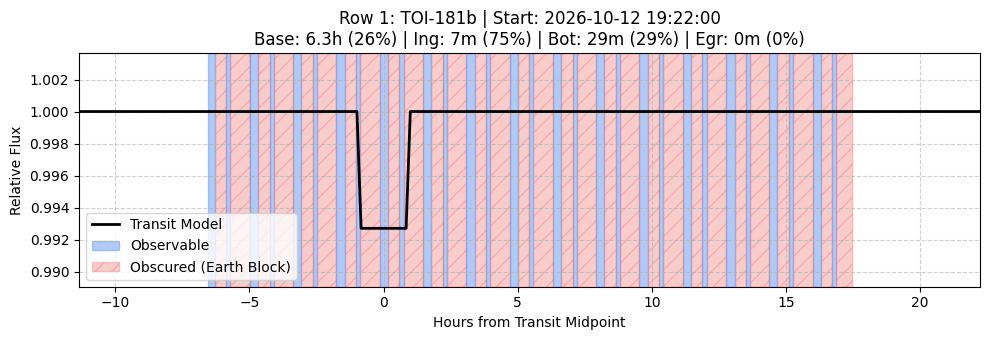

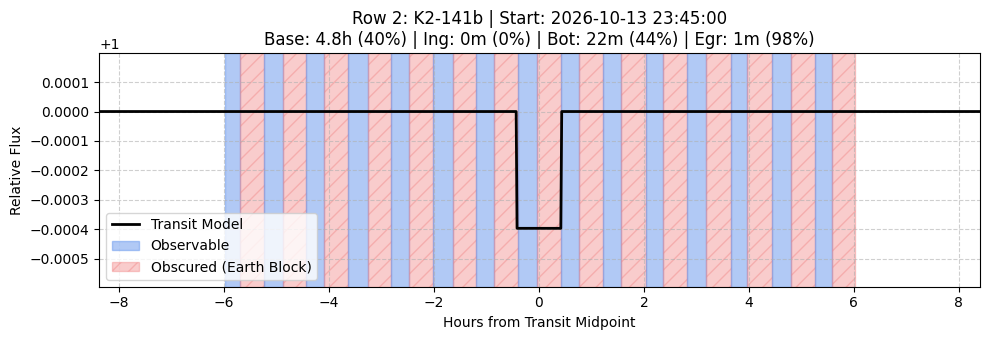

In [12]:
df_results = analyze_and_plot_observations(df, param_cache, plot=True, rows=[0, 1, 2,]).drop(columns=['Row'], inplace=False)


**4. View the final tabular breakdown**

In [13]:
display(df_results)

,Target,Obs Start,Baseline (hrs),Baseline (%),Ingress Cap (min),Ingress Cap (%),Bottom Cap (min),Bottom Cap (%),Egress Cap (min),Egress Cap (%)
0,K2-141b,2026-10-12 05:56:00,4.97,41.4,0,0.0,23,46.0,0,0.0
1,TOI-181b,2026-10-12 19:22:00,6.32,26.3,7,74.5,29,28.8,0,0.0
2,K2-141b,2026-10-13 23:45:00,4.77,39.7,0,0.0,22,44.0,1,98.3
